# **Predicting Individuals' Stress Levels, Anxiety & Depression Scores Based on Their Gaming Habits**

Asli Zeybek (ID: 40249063)

April 19, 2026

COMP-432

## **Abstract**
The goal of the project will be to predict gamer’s stress/anxiety/depression levels (3 labels) using machine learning and deep learning techniques. The dataset used is synthetic data that contains 1,000,000 entries, and consists of 40 features that include individuals’ gaming behaviour, lifestyle habits, psychological health indicators, social environment, physical health indicators, as well as productivity/performance indicators. To do this, first, ExtraTree Regressor (ML) with RandomizedSearchCV for hyperparameter tuning will be used, followed by TabNet (DL) and CatBoost. As for the performance metrics, the following were calculated for each of the models: Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), and R-Squared (R2). Overall, we found that ExtraTreesRegressor performed better (by a tiny margin).


## **Introduction**
The problem this project aims to solve is to predict what kind of effect an individual’s gaming habits and demographic characteristics may have on their mental health. In recent years, with the rise of digital gaming platforms, there has been a spike in hours one spends gaming. Even younger generations have traded cars and toys for electronics and online games. This is why it is crucial to understand and predict whether one’s gaming habits and demographic characteristics lead to higher stress. Discovering patterns may help figuring which factors cause elevated stress/anxiety/depression levels. The dataset used was this synthetic data on Kaggle: "gaming_mental_health_10M_40features.csv" // [link](https://www.kaggle.com/datasets/sharmajicoder/gaming-and-mental-health/code). The main challenges may include class imbalances, as well as noisy data. Handling these challenges is crucial to get an accurate prediction.


## **Methodology**
The previous studies have trained a Random Forest Regressor, a Logistic Regression, (Baseline) Ridge, LightGBM Classifier, XGBoost Classifier, SGD Regressor, and Hist Gradient Boosting. The main difference between these proposed solutions and my approach is the use of deep learning models and machine learning models to do a MultiTask Learning (Regression) (with 3 targets)  –  ExtraTree Regressor, TabNet, and CatBoost. The first step is analyzing the data, by performing an EDA. Followed by data preprocessing, where we standardize the features and split the data into train, validation and test sets. As for the model training part, initially, I was going to use GridSearchCV as my technique for hyperparameter tuning, however, RandomizedSearch was found to be much faster and scales to large datasets. First, I tuned on a subset of the gaming_data (100,000), then used RandomizedSearchCV for hyperparameter tuning. Once it found the best parameters, I retrained best parameters on the full dataset. Then, the next model is a deep learning model: TabNet (more specifically TabNetRegressor in this case). The third model used is CatBoost (Regressor).

In [ ]:
!gdown 1NcDvsq4CdPYSrc1G6aSGuwUKWmX01ogw
!pip install pytorch-tabnet --quiet
!pip install tab-transformer-pytorch --quiet
!pip install catboost --quiet

Downloading...
From (original): https://drive.google.com/uc?id=1NcDvsq4CdPYSrc1G6aSGuwUKWmX01ogw
From (redirected): https://drive.google.com/uc?id=1NcDvsq4CdPYSrc1G6aSGuwUKWmX01ogw&confirm=t&uuid=8c9f5063-f02f-4035-b16f-78868c3644dc
To: /content/gaming_mental_health_10M_40features.csv
100% 173M/173M [00:03<00:00, 45.7MB/s]


In [ ]:
# import necessary modules/libraries
import os, warnings, random
warnings.filterwarnings("ignore")

# Main/Visualization libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning libraries
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from catboost import CatBoostRegressor

# Deep learning libraries
import torch
import torch.nn as nn
from pytorch_tabnet.tab_model import TabNetRegressor

# Training params
CSV_FILE = "gaming_mental_health_10M_40features.csv"
SEED        = 42
EPOCHS      = 20
DEVICE      = "cuda" if torch.cuda.is_available() else "cpu"
TARGETS = ['stress_level', 'anxiety_score', 'depression_score']

# Repro
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

# Retrieve Data / Load Data
gaming_data = pd.read_csv(CSV_FILE)
print(gaming_data.shape)

(1000000, 39)


## **1. Data Analysis**
In this section, the data will be cleaned, analyzed and summarized. To understand the structure of the data, I used EDA and different visualizations tools. More specifically, to aEDA is the approach used here to detect anomalies/outliers, missing values, class imbalances that could impact the models used later on. It

In [ ]:
# Peek at first 5 rows of the gaming_data
gaming_data.head()

,age,gender,income,daily_gaming_hours,weekly_sessions,years_gaming,sleep_hours,caffeine_intake,exercise_hours,stress_level,...,parental_supervision,loneliness_score,aggression_score,happiness_score,bmi,screen_time_total,eye_strain_score,back_pain_score,competitive_rank,internet_quality
0,51,Female,8615,3.68,22,17,5.26,1.00,0.18,3,...,0,2.87,3.19,5.20,19.69,4.71,5.71,4.81,80,10
1,41,Female,39453,5.70,34,16,9.20,0.70,1.44,8,...,7,4.17,7.73,5.40,26.37,6.62,6.77,3.99,57,2
2,27,Male,40466,1.58,8,22,7.39,2.24,3.15,3,...,9,9.38,2.85,5.17,25.15,9.30,2.16,4.75,59,10
3,55,Male,51076,6.11,39,24,7.99,1.65,2.80,1,...,5,8.24,7.19,8.62,26.42,13.81,4.72,5.37,89,1
4,20,Male,86116,3.65,17,0,7.12,1.02,1.01,2,...,9,6.65,2.53,9.71,25.75,10.74,3.90,6.44,15,10


In [ ]:
# Generate descriptive statistics of the gaming_data
gaming_data.describe()

,age,income,daily_gaming_hours,weekly_sessions,years_gaming,sleep_hours,caffeine_intake,exercise_hours,stress_level,anxiety_score,...,parental_supervision,loneliness_score,aggression_score,happiness_score,bmi,screen_time_total,eye_strain_score,back_pain_score,competitive_rank,internet_quality
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.00000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,...,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,35.986005,77497.675955,3.999255,19.997540,12.002512,7.00053,1.997513,1.999008,5.497577,4.998644,...,4.996374,4.998520,5.000455,5.981822,24.003916,8.002032,4.998675,4.018777,49.448122,5.503339
std,13.557163,41851.540503,2.826307,11.253438,7.207838,1.50111,1.996174,1.999545,2.873248,1.977711,...,3.160810,1.977601,1.980307,1.956122,3.999927,3.998987,1.979308,1.956123,28.873153,2.871940
min,13.000000,5000.000000,0.000000,1.000000,0.000000,-0.17000,0.000000,0.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,4.450000,0.070000,0.000000,0.000000,0.000000,1.000000
25%,24.000000,41258.000000,1.920000,10.000000,6.000000,5.99000,0.580000,0.580000,3.000000,3.650000,...,2.000000,3.650000,3.650000,4.650000,21.300000,5.070000,3.650000,2.660000,24.000000,3.000000
50%,36.000000,77521.000000,3.360000,20.000000,12.000000,7.00000,1.390000,1.390000,5.000000,5.000000,...,5.000000,5.000000,5.000000,6.000000,24.000000,7.350000,5.000000,4.000000,49.000000,6.000000
75%,48.000000,113697.000000,5.380000,30.000000,18.000000,8.01000,2.770000,2.770000,8.000000,6.350000,...,8.000000,6.350000,6.350000,7.350000,26.700000,10.220000,6.350000,5.350000,74.000000,8.000000
max,59.000000,149999.000000,30.420000,39.000000,24.000000,14.02000,26.900000,26.480000,10.000000,10.000000,...,10.000000,10.000000,10.000000,10.000000,43.600000,46.600000,10.000000,10.000000,99.000000,10.000000


In [ ]:
# Check how many numerical/categorical columns the gaming data contains
numerical_cols = gaming_data.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = gaming_data.select_dtypes(include=['object']).columns
print(f'{len(numerical_cols)} Numerical Column(s) and {len(categorical_cols)} Categorical Column(s).\n')

# Display dataset columns info
gaming_data.info()

38 Numerical Column(s) and 1 Categorical Column(s).

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 39 columns):
 #   Column                      Non-Null Count    Dtype  
---  ------                      --------------    -----  
 0   age                         1000000 non-null  int64  
 1   gender                      1000000 non-null  object 
 2   income                      1000000 non-null  int64  
 3   daily_gaming_hours          1000000 non-null  float64
 4   weekly_sessions             1000000 non-null  int64  
 5   years_gaming                1000000 non-null  int64  
 6   sleep_hours                 1000000 non-null  float64
 7   caffeine_intake             1000000 non-null  float64
 8   exercise_hours              1000000 non-null  float64
 9   stress_level                1000000 non-null  int64  
 10  anxiety_score               1000000 non-null  float64
 11  depression_score            1000000 non-null  float64
 12  soci

In [ ]:
# Check for missing values
print(f'There are {gaming_data.isnull().sum().sum()} missing values in the data.\n')
# Check for duplicate rows
print(gaming_data[gaming_data.duplicated()])

There are 0 missing values in the data.

Empty DataFrame
Columns: [age, gender, income, daily_gaming_hours, weekly_sessions, years_gaming, sleep_hours, caffeine_intake, exercise_hours, stress_level, anxiety_score, depression_score, social_interaction_score, relationship_satisfaction, academic_performance, work_productivity, addiction_level, multiplayer_ratio, toxic_exposure, violent_games_ratio, mobile_gaming_ratio, night_gaming_ratio, weekend_gaming_hours, friends_gaming_count, online_friends, streaming_hours, esports_interest, headset_usage, microtransactions_spending, parental_supervision, loneliness_score, aggression_score, happiness_score, bmi, screen_time_total, eye_strain_score, back_pain_score, competitive_rank, internet_quality]
Index: []

[0 rows x 39 columns]


We can see that there aren't any missing values and/or duplicate rows in the gaming_data.

In [ ]:
# Proportion of Male/Female/Other values in 'gender' column
print(gaming_data["gender"].value_counts(normalize=True))

gender
Male      0.480581
Female    0.479579
Other     0.039840
Name: proportion, dtype: float64


In [ ]:
# Let's now have a glance at the proportion of values in each tagert variables
print(gaming_data['stress_level'].value_counts())
print(f'\n{gaming_data['anxiety_score'].value_counts()}')
print(f'\n{gaming_data['depression_score'].value_counts()}')

stress_level
4     100347
1     100287
2     100169
10    100098
8     100071
5     100041
7      99961
3      99726
9      99702
6      99598
Name: count, dtype: int64

anxiety_score
0.00     6415
10.00    6288
4.88     2081
4.85     2073
4.90     2073
         ... 
9.80       86
9.83       86
0.02       85
9.98       85
0.09       85
Name: count, Length: 1001, dtype: int64

depression_score
0.00     22890
10.00    22853
5.05      1707
5.15      1677
5.40      1672
         ...  
9.95       206
9.98       204
9.96       203
9.99       199
0.06       198
Name: count, Length: 1001, dtype: int64


Below are helper methods used to for plotting.

In [ ]:
def draw_countplot_feature(label, title):
  """Draws countplot of the feature given as input.

  Arguments:
    label: label name (among stress_level, anxiety_score, depression_score) to plot
    title: title given to the plot
  """
  plt.figure(figsize=(8,6))
  ax = sns.countplot(x=label, data=gaming_data, palette='pastel')
  for i in range(0, label.nunique()):
    ax.bar_label(ax.containers[i])
  plt.title(title)
  plt.show()

def draw_hist_feature(label, title, binwidth=0.15):
  """Draws histogram of the feature given as input.

  Arguments:
    label: label name (among stress_level, anxiety_score, depression_score) to plot
    title: title given to the plot
    binwidth: width of bins/range of values grouped into each bar shown on the histogram
  """
  plt.figure(figsize=(8,6))
  sns.histplot(x=label, data=gaming_data, bins=100, kde=True, alpha=0.5)
  plt.title(title)
  plt.show()

def draw_actual_vs_pred(y_test, y_pred, model):
  """Displays a scatterplot of actual vs predicted values of given model

  Arguments:
    y_true: actual, ground truth labels
    y_pred: predicted values
    model: name of the model used
  """
  plt.scatter(y_test, y_pred, alpha=0.5)
  plt.xlabel("Actual")
  plt.ylabel("Predicted")
  plt.title(f"Actual vs Predicted {model}")
  plt.show()

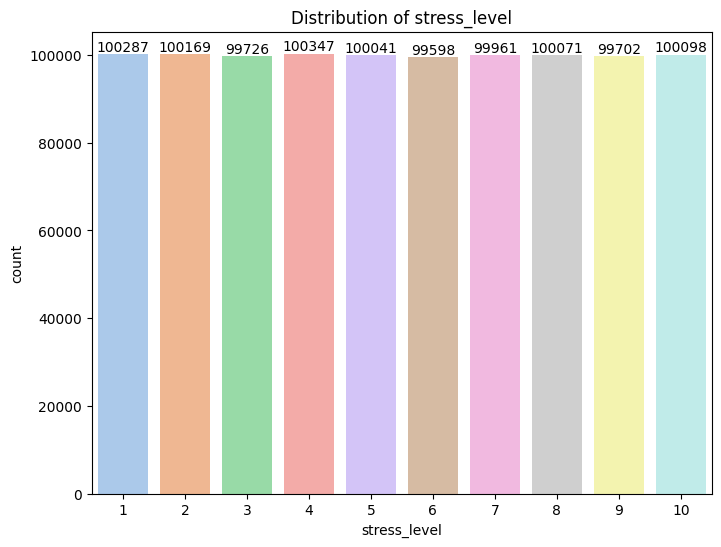

In [ ]:
draw_countplot_feature(gaming_data['stress_level'], 'Distribution of stress_level')

Uniform distribution indicates balanced classes, not class imbalance.

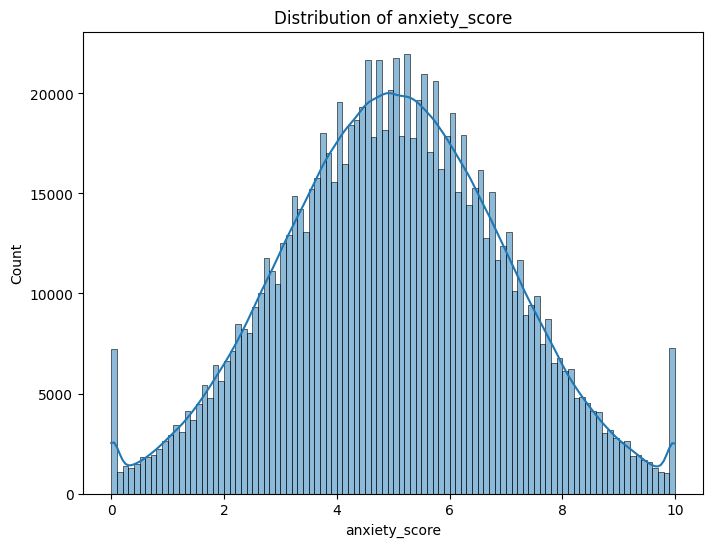

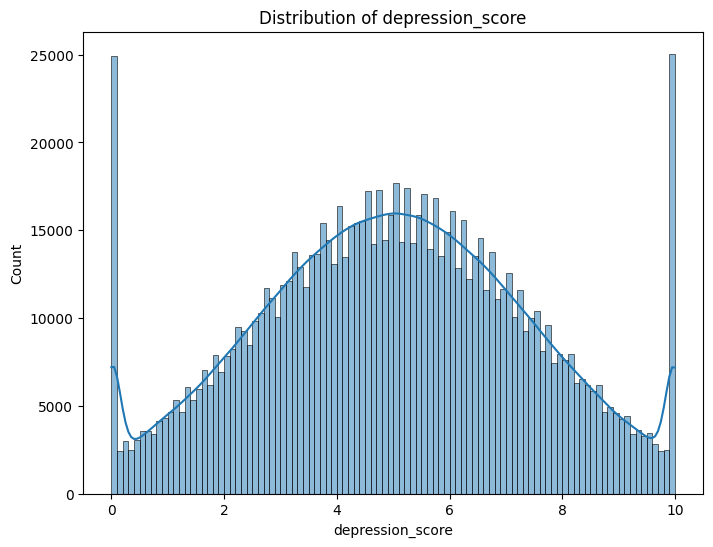

In [ ]:
# plotting histogram of distribution of anxiety_score, and depression_score
draw_hist_feature(gaming_data['anxiety_score'], 'Distribution of anxiety_score')
draw_hist_feature(gaming_data['depression_score'], 'Distribution of depression_score')

Normal (Gaussian) distribution implies that the categories in the middle are common scores, whereas those on the tails are less common, but the overall structure is symmetrical.
The spikes at 0 and 10 make sense in the context of this data/project because these are mental health score. Simply put, some may not be depressed/anxious at all, which would explain the 0, vice-versa.

Top 5 most correlated features with stress_level
stress_level                  1.000000
microtransactions_spending    0.001832
internet_quality              0.001415
happiness_score               0.001206
eye_strain_score              0.000845
Name: stress_level, dtype: float64


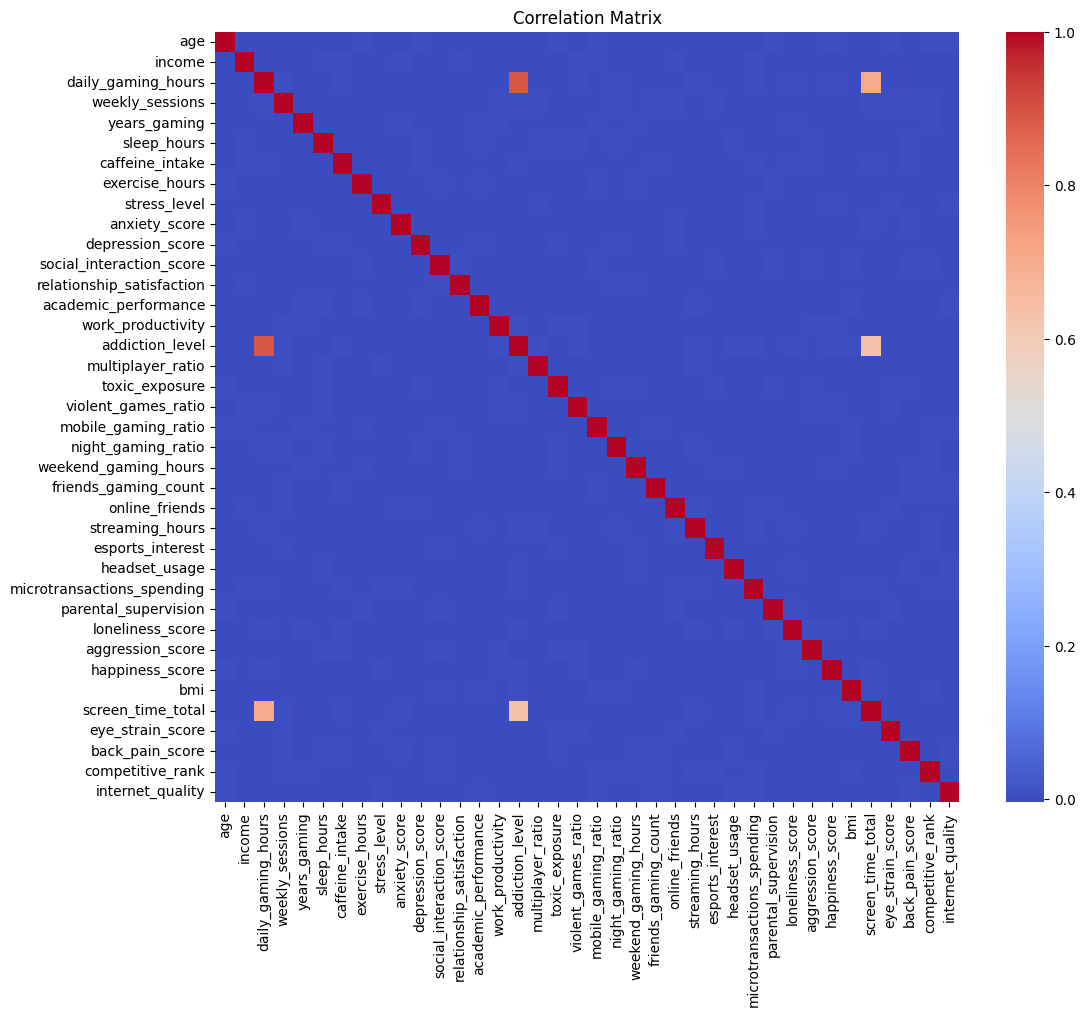

In [ ]:
# Let's look at the top correlated features in this dataset with stress_level
print('Top 5 most correlated features with stress_level')
corr_stress = gaming_data[numerical_cols].corr()['stress_level']
print(corr_stress.sort_values(ascending=False).head())

# Calculate the correlation
corr_matrix = gaming_data.corr(numeric_only=True)

# Display the correlaiton scores as a heatmap
plt.figure(figsize=(12,10))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

By the strong presence of blue tiles (correlation of 0.0) on the heatmap, we can see that in this synthetic data, the columns (features & labels) are not correlated. Independent variables.
We can also see that the top 5 correlated features with stress_level are still pretty low and do not indicate any strong relationship.

## **2. Data Preprocessing**
We saw earlier that this dataset contains 1 categorical column. This means that we need to encode it [the 'gender' column] using LabelEncoder().

In [ ]:
# Create a copy of the original data
gaming_data = gaming_data.copy()

# Create an instance of the LabelEncoder
le = LabelEncoder()

# Encode the categorical col 'gender'
gaming_data['gender'] = le.fit_transform(gaming_data['gender'].astype(str))
targets = ['stress_level', 'anxiety_score', 'depression_score']

# Define feature variables (X) and target variables (y)
X = gaming_data.drop(columns=TARGETS)
y = gaming_data[targets].astype(float)

In [ ]:
# Split data into train and test sets
X_remaining, X_test, y_remaining, y_test = train_test_split(X, y, test_size=0.15, random_state=SEED)

# Split the remaining data into train and validation sets
X_train, X_val, y_train, y_val = train_test_split(X_remaining, y_remaining, test_size=0.15/(1-0.15), random_state=42)

# Create an instance of the StandardScaler
scaler = StandardScaler()

# Fit and transform data
X_train_scaled = scaler.fit_transform(X_train)  # fit only on train
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)  # careful: fit_transform can cause data leakage

# Convert the data to numpy.array (prerequisite for TabNet)
X_train_np = np.asarray(X_train_scaled, dtype=np.float32)
y_train_np = np.asarray(y_train, dtype=np.float32)
X_val_np = np.asarray(X_val_scaled, dtype=np.float32)
y_val_np = np.asarray(y_val, dtype=np.float32)
X_test_np = np.asarray(X_test_scaled, dtype=np.float32)
y_test_np = np.asarray(y_test, dtype=np.float32)

## **3. Model Selection/Training (3)**
### **Model 1: ExtraTreesRegressor** (with RandomizedSerachCV for Hyperparameter Tuning)

In [ ]:
def calculate_metrics(y_true, y_pred, model):
  """Computes performance metrics for each model (rmse, mae and r-squared)

  Arguments:
    y_true: actual, ground truth labels
    y_pred: predicted values
    model: name of the model used
  Returns:
    rmse: calculated rmse value (of the given model)
    mae: calculated mae value
    r2: calculated r2 value
  """
  rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
  mae  = float(mean_absolute_error(y_true, y_pred))
  r2   = float(r2_score(y_true, y_pred))

  # Display the calculated metrics values
  print(f'\n{model} Metrics:\nRMSE:{rmse}\nMAE: {mae}\nR2: {r2}')
  return rmse, mae, r2

In [ ]:
# Model 1: ExtraTreesRegressor
print('--- MODEL 1: EXTRATREESREGRESSOR ---\n')

# Initialize the ExtraTreesRegressor
etr = ExtraTreesRegressor(random_state=SEED)

# Define the parameter space using distributions
param_distributions = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None]
}

# Initialize RandomizedSearchCV (used for Hyperparameter Tuning)
randomized_search = RandomizedSearchCV(
    estimator = etr,
    param_distributions = param_distributions,
    n_iter = 10,  # it will randomly pick 10 combinations to test
    cv = 3,
    scoring = 'r2',
    verbose = 2,
    random_state = SEED,
    n_jobs = -1   # parallel
)

# Take a sample from the original 1M data and train the RandomizedSearch on 100K rows instead (subset)
X_sample, _, y_sample, _ = train_test_split(X, y, train_size=100000, random_state=42)
# Run the search
randomized_search.fit(X_sample, y_sample)

# Print best params
print(randomized_search.best_params_)

# Refit best params
best_params = randomized_search.best_params_
retrained_etr = ExtraTreesRegressor(**best_params, random_state=SEED, n_jobs=-1)

# Train the model
retrained_etr.fit(X_train_scaled, y_train)

# Predict on test set
preds_etr = retrained_etr.predict(X_test_scaled)

# Compute metrics (RMSE, MAE, R-SQUARED)
rmse_etr, mae_etr, r2_etr = calculate_metrics(y_test, preds_etr, 'ExtraTreeRegressor')

--- MODEL 1: EXTRATREESREGRESSOR ---

Fitting 3 folds for each of 10 candidates, totalling 30 fits
{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 10}

ExtraTreeRegressor Metrics:
RMSE:2.4428402555763906
MAE: 2.013275427441985
R2: -1.699367265147374e-05


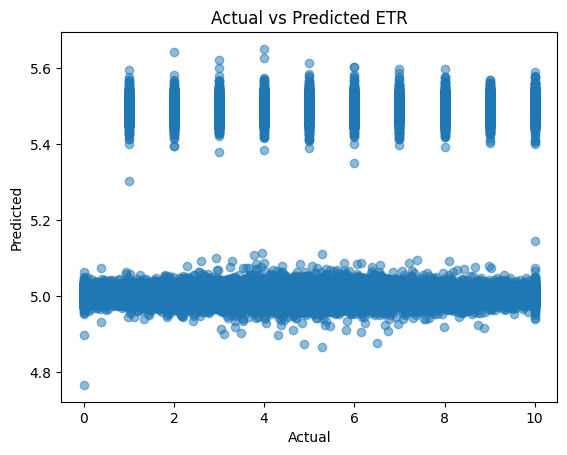

In [ ]:
draw_actual_vs_pred(y_test, preds_etr, 'ETR')

### **Model 2: TabNet** (Regressor)

In [ ]:
# Model 2: TabNet Regressor
print('--- MODEL 2: TABNET REGRESSOR ---\n')

# Define TabNet parameters
tabnet_params = dict(
    n_steps = 3,
    n_d = 32,     # size of the decision steps
    n_a = 32,     # size of the attention steps
    gamma = 1.3,  # default 1.3
    optimizer_fn = torch.optim.Adam,
    optimizer_params = {'lr': 1e-3},
    scheduler_fn = torch.optim.lr_scheduler.StepLR,
    scheduler_params = {'step_size': 10, 'gamma': 0.9},
    verbose = 10,
    seed = SEED
)

# Initialize the TabNet
tabnet_model = TabNetRegressor(**tabnet_params)

# Train the model
tabnet_model.fit(
    X_train = X_train_np,
    y_train = y_train_np,
    eval_set = [(X_val_np, y_val_np)],
    eval_name = ['validation'],
    eval_metric = ['rmse', 'mae'],
    max_epochs = 100,
    patience = 10,
    batch_size = 4096,
)

# Predict on test set
preds_tabnet = tabnet_model.predict(X_test_np)

# Calculate metrics (RMSE, MAE, R-SQUARED)
rmse_tb, mae_tb, r2_tb = calculate_metrics(y_test, preds_tabnet, 'TabNet')

--- MODEL 2: TABNET REGRESSOR ---

epoch 0  | loss: 12.22891| validation_rmse: 2.50521 | validation_mae: 2.05429 |  0:00:40s
epoch 10 | loss: 5.99351 | validation_rmse: 2.44637 | validation_mae: 2.01439 |  0:05:14s
epoch 20 | loss: 5.98623 | validation_rmse: 2.44592 | validation_mae: 2.01421 |  0:09:33s
epoch 30 | loss: 5.98304 | validation_rmse: 2.44574 | validation_mae: 2.01381 |  0:13:44s
epoch 40 | loss: 5.98211 | validation_rmse: 2.44569 | validation_mae: 2.01395 |  0:17:55s

Early stopping occurred at epoch 46 with best_epoch = 36 and best_validation_mae = 2.01371

TabNet Metrics:
RMSE:2.444065446323872
MAE: 2.0138051509857178
R2: -0.0009909868240356445


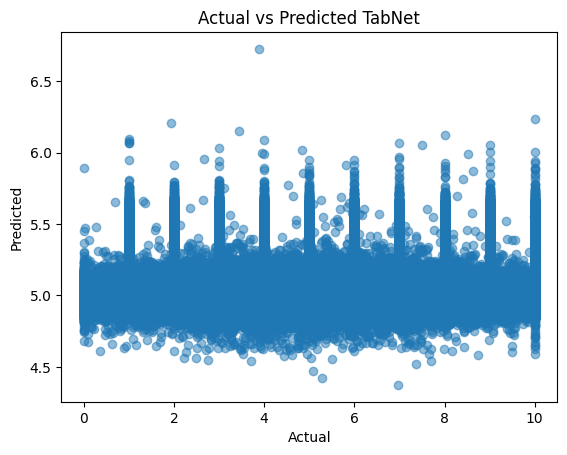

In [ ]:
draw_actual_vs_pred(y_test, preds_tabnet, 'TabNet')

### **Model 3: CatBoost** (Regressor)

--- MODEL 3: CATBOOST REGRESSOR ---

0:	learn: 4.2347246	total: 68.7ms	remaining: 34.3s
100:	learn: 4.2302584	total: 2.09s	remaining: 8.25s
200:	learn: 4.2260088	total: 3.58s	remaining: 5.33s
300:	learn: 4.2219423	total: 5.03s	remaining: 3.32s
400:	learn: 4.2178759	total: 6.49s	remaining: 1.6s
499:	learn: 4.2138603	total: 7.96s	remaining: 0us

CatBoost Metrics:
RMSE:2.4436673752361564
MAE: 2.013549725211886
R2: -0.0006909117767865217


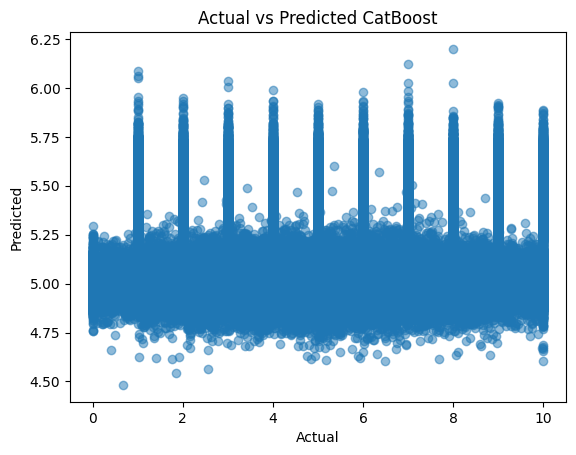

In [ ]:
# Model 3: CatBoost Regressor
print('--- MODEL 3: CATBOOST REGRESSOR ---\n')

# Initialze CatBoostRegressor
catboost_model = CatBoostRegressor(
    iterations = 500,
    depth = 6,
    loss_function = 'MultiRMSE',  # rmse for multioutput
    learning_rate = 0.1,
    random_seed = SEED,
    task_type = 'GPU',
    verbose = 100
)

# Train the model
catboost_model.fit(X_train_scaled, y_train)

# Predict on test set
preds_cb = catboost_model.predict(X_test_scaled)

# Compute metrics (RMSE, MAE, R-SQUARED)
rmse_cb, mae_cb, r2_cb = calculate_metrics(y_test, preds_cb, 'CatBoost')

# Display actual vs predicted
draw_actual_vs_pred(y_test, preds_cb, 'CatBoost')

## **Experimental Results**


In [ ]:
results = pd.DataFrame({
    'Model': ['CatBoost', 'TabNet', 'ExtraTreesRegressor'],
    'RMSE': [rmse_cb, rmse_tb, rmse_etr],
    'MAE': [mae_cb, mae_tb, mae_etr],
    'R2': [r2_cb, r2_tb, r2_etr]
})

results

,Model,RMSE,MAE,R2
0,CatBoost,2.443667,2.013550,-0.000691
1,TabNet,2.444065,2.013805,-0.000991
2,ExtraTreesRegressor,2.442840,2.013275,-0.000017


The RMSE, MAE, R-Squared scores of all three models are almost identical. However, if we had to answer the question of which model performed better, we would have to say ExtraTreesRegressor because its R-Squared is the one closest to 0.0, its MAE is (by a bit) the lowest out of all three, and its RMSE is also the lowest. Simply put, lower RMSE and MAE scores are better when dealing with regression analysis, which is why we say here that ExtraTreesRegressor performed better, even though from the bigger picture, all three models have performed the same.

## **Conclusions**
All in all, since the dataset used in this project is a synthetic data, and as we have seen, the features and targets seem to have no relationship (if they do, then it's a very weak one). Below we can see the correlation of the top 5 features with stress_level.

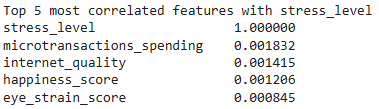

Even the top five most correlated features have a very small correlation. This would explain why our values in our performance metrics are not necessarily good, and it would also explain why all three models' performance is relatively the same. If this had been real data, then we would have seen differences in each models' performance, since features and targets would have meaningful relationships, and stronger correlations among themselves.

## **References**

[1] https://www.kaggle.com/datasets/sharmajicoder/gaming-and-mental-health/code

[2] https://pypi.org/project/pytorch-tabnet/